In [ ]:
pip install pandas pyxlsb

In [ ]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
data_path = '/content/drive/Shared drives/EARL/Students/Kaitlyn/Excel Files and Code'

In [ ]:
import re
from datetime import datetime

def is_valid_time(time_string):
    try:
        # Attempt to parse the string as a time with the format HH:MM:SS
        datetime.strptime(time_string, "%H:%M:%S")
        return True
    except ValueError:
        # If parsing fails, the format is invalid
        return False

def check_values(array):
  for item in array:
    # Check if any value is NaN or empty
    if pd.isna(item) or str(item).strip() == '':
      return False
  return True

def extract_data(file_path):
  df = pd.read_excel(file_path, header=0)

  values = []

  for i, c in enumerate(df.columns):
    for j, value in enumerate(df[c]):
      if is_valid_time(str(value)):
        try:
          time = df.at[j, df.columns[i]]
          concentration = df.at[j, df.columns[i + 1]]
          count = df.at[j, df.columns[i + 2]]

          if (check_values([time, concentration, count])):
            values.append([time, concentration, count])
        except:
          continue

  return values

Run everything above before starting data analysis below

In [ ]:
"Data for : "

data1 = extract_data('/content/drive/Shared drives/EARL/Students/Kaitlyn/Excel Files and Code/2025_CONTROL_RUN_3.xlsx')
print(len(data1))
concentration1 = []

for i in range(len(data1)):
   concentration1.append(data1[i][1])

print(concentration1)
print(len(concentration1))

time1 = np.arange(0, len(concentration1), 1)
print(time1)

dconc_dt_1 = np.gradient(concentration1, time1)

1733
[590.2, 597.4, 625.5, 606.8, 583.2, 588.1, 560.6, 591.9, 583.1, 569.2, 592.7, 575.7, 606.8, 551.5, 636.1, 587.8, 518.4, 609.1, 544.4, 593.7, 546.6, 593.8, 540.8, 580.8, 566.7, 515, 534.9, 543.1, 565.5, 547.9, 546.6, 538.5, 488.2, 473.3, 469.2, 487.7, 450.9, 547.9, 504.6, 563.1, 479.8, 438.4, 503.1, 513, 504, 534, 490.2, 489.7, 479, 519.4, 479.3, 482.9, 524.5, 510.3, 500.6, 515.9, 497.1, 502.2, 517.4, 523.6, 511.7, 533.3, 522, 521.1, 491.5, 474.5, 519.3, 467.3, 560.5, 523.5, 455.7, 1856.6, 316200, 376100, 368600, 476400, 625100, 659200, 684700, 691500, 694600, 673100, 659500, 715800, 750800, 693900, 668600, 675200, 635800, 597300, 560000, 522700, 546800, 549300, 543500, 558800, 580700, 596800, 603700, 611200, 612100, 608300, 608900, 602400, 597900, 597700, 598200, 596600, 591100, 587800, 587400, 587300, 587100, 584100, 578500, 577000, 574600, 574400, 567600, 560200, 560600, 557300, 556800, 555300, 550500, 546900, 544100, 538500, 539200, 540300, 539000, 538300, 531500, 527300, 52700

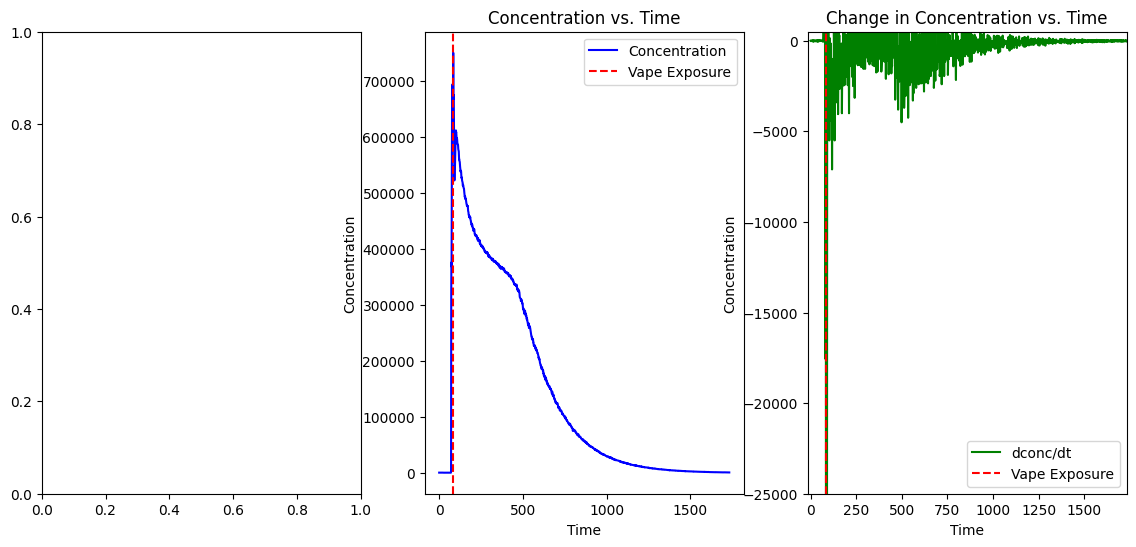

In [ ]:

max_index_1 = np.argmax(concentration1)
max_time_1 = time1[max_index_1]

# Create a figure with two subplots
fig, axs = plt.subplots(1, 3, figsize=(14, 6))


# Line plot of concentration over time
axs[1].plot(time1, concentration1, label='Concentration', color='blue')
axs[1].set_title('Concentration vs. Time')
axs[1].set_xlabel('Time')
axs[1].set_ylabel('Concentration')
axs[1].axvline(max_time_1, color='red', linestyle='--', label='Vape Exposure')
axs[1].legend()



#Line plot of change in concentration over time
axs[2].plot(time1, dconc_dt_1, label='dconc/dt', color='green')
axs[2].set_title('Change in Concentration vs. Time')
axs[2].set_xlabel('Time')
axs[2].set_ylabel('Concentration')
axs[2].axvline(max_time_1, color='red', linestyle='--', label='Vape Exposure')
axs[2].set_xlim(max_time_1-100, len(concentration1))
axs[2].set_ylim(-25000, 500)
axs[2].legend()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# --- Exponential decay model ---
def exp_decay(t, A, k, C):
    return A * np.exp(-k * t) + C

# --- 1. Identify vape exposure (max concentration index) ---
max_index = np.argmax(concentration1)
phase_one_start = max_index

# Apply 30s buffer to phase one start
phase_one_start_time = time1[phase_one_start] + 30  # Add 30s buffer
phase_one_start = np.where(time1 >= phase_one_start_time)[0][0]

# --- 2. Derivatives for inflection candidates ---
dconc_dt = np.gradient(concentration1, time1)
d2conc_dt2 = np.gradient(dconc_dt, time1)

# --- 3. Find inflection points after vape exposure + 100s ---
inflection_candidates = np.where(np.diff(np.sign(d2conc_dt2)))[0]
inflection_candidates = inflection_candidates[inflection_candidates > phase_one_start + 100]

best_error = np.inf
best_split = None
best_popt_p1 = None
best_popt_p2 = None

# --- 4. Test each inflection candidate and compute total error ---
for candidate in inflection_candidates:
    t_p1, c_p1 = time1[phase_one_start:candidate], concentration1[phase_one_start:candidate]
    t_p2, c_p2 = time1[candidate:], concentration1[candidate:]

    if len(t_p1) < 5 or len(t_p2) < 5:
        continue

    try:
        popt_p1, _ = curve_fit(exp_decay, t_p1, c_p1, p0=(1e6, 0.01, 1e5),
                               bounds=([0, 0, 0], [np.inf, np.inf, np.inf]), maxfev=10000)
        popt_p2, _ = curve_fit(exp_decay, t_p2, c_p2, p0=(1e6, 0.005, 1e5),
                               bounds=([0, 0, 0], [np.inf, np.inf, np.inf]), maxfev=10000)

        err_p1 = np.sum((c_p1 - exp_decay(t_p1, *popt_p1))**2)
        err_p2 = np.sum((c_p2 - exp_decay(t_p2, *popt_p2))**2)
        total_error = err_p1 + err_p2

        if total_error < best_error:
            best_error = total_error
            best_split = candidate
            best_popt_p1 = popt_p1
            best_popt_p2 = popt_p2
    except:
        continue

# --- 5. Assign best split with e-folding buffer ---
if best_split is not None:
    inflection_time = time1[best_split]

    # Compute τ (e-folding times) and cap them to avoid excessive shift
    tau_top = min(1 / best_popt_p1[1], 50)      # cap at 50s
    tau_bottom = min(1 / best_popt_p2[1], 50)

    # Buffer before and after inflection
    phase_one_end_time = max(phase_one_start_time + 1, inflection_time - tau_top)
    phase_two_start_time = inflection_time + tau_bottom

    # Convert buffered times to indices
    phase_one_end = np.where(time1 >= phase_one_end_time)[0][0]
    phase_two_start = np.where(time1 >= phase_two_start_time)[0][0]

    # Ensure valid ordering
    if phase_one_end <= phase_one_start:
        phase_one_end = best_split - 1
    if phase_two_start <= phase_one_end:
        phase_two_start = best_split
else:
    # Fallback: no inflection found
    phase_one_end = phase_one_start + 100
    phase_two_start = phase_one_end

# --- 6. Phase Two end: first index <= 999 ---
phase_two_candidates = np.where(np.array(concentration1) <= 999)[0]
phase_two_candidates = phase_two_candidates[phase_two_candidates > phase_two_start]
phase_two_end = phase_two_candidates[0] if len(phase_two_candidates) > 0 else len(concentration1) - 1

# --- Print results ---
print(f"Phase One: Start={phase_one_start}, End={phase_one_end}")
print(f"Phase Two: Start={phase_two_start}, End={phase_two_end}")


Phase One: Start=114, End=420
Phase Two: Start=520, End=1713


In [ ]:
# ---- Utilities: always convert times -> indices via time array ----
def idx_at_or_after(t_array, t_sec):
    """small helper: first index where time >= t_sec; clamps to last index."""
    i = np.searchsorted(t_array, t_sec, side="left")
    return min(i, len(t_array) - 1)

# 0) Vape exposure time (time of global max)
t_exposure = time1[max_index]

# 1) t1 = start of Phase I (exposure + 30 s buffer), in SECONDS
t1 = t_exposure + 30.0
i1 = idx_at_or_after(time1, t1)   # this is the *index* where Phase I begins

# 2) If you want the 100-second rule for inflection *in seconds*, re-filter:
#    (replace your earlier "inflection_candidates > phase_one_start + 100")
#    Keep inflection candidates whose time is >= t1 + 100 s
if 'inflection_candidates' in locals():
    inflection_candidates = inflection_candidates[time1[inflection_candidates] >= (t1 + 100.0)]

# If you already selected best_split above, turn it into seconds now:
if best_split is not None:
    t_inflect_raw = time1[best_split]  # original inflection time (unbuffered)

    # 3) Apply your ±τ buffers *in seconds* and recompute indices
    tau_top    = min(1.0 / best_popt_p1[1], 50.0)  # s
    tau_bottom = min(1.0 / best_popt_p2[1], 50.0)  # s

    t2_start = max(t1 + 1.0, t_inflect_raw - tau_top)   # Phase I end time
    t2       = t_inflect_raw                             # the split/inflection time to report
    t2_end   = t_inflect_raw + tau_bottom                # Phase II start time

    i1_end = idx_at_or_after(time1, t2_start)
    i2     = idx_at_or_after(time1, t2)       # index of inflection (for reference)
    i2_start = idx_at_or_after(time1, t2_end)

    # 4) t3 = end of Phase II (first time <= 999)
    #     (you already computed phase_two_end; convert it to seconds)
    t3 = time1[phase_two_end]
    i3 = phase_two_end
else:
    # Fallback if no split found
    t2 = time1[phase_one_end]  # rough
    i2 = phase_one_end
    t3 = time1[phase_two_end]
    i3 = phase_two_end

# ---- Print a clean summary in seconds (and indices for debugging) ----
print("\n=== Derived Key Times (seconds) ===")
print(f"t1  (Phase I start, exposure+30s): {t1:.2f} s   [index {i1}]")
print(f"t2  (Inflection/split time)      : {t2:.2f} s   [index {i2}]")
print(f"t3  (Phase II end, <=1000 #/cm³) : {t3:.2f} s   [index {i3}]")

# Optional sanity checks to understand any mismatch you saw:
print("\nSanity checks:")
print(f"Sampling step ~ {np.median(np.diff(time1)):.3f} s/sample")
print(f"Index distance from max to i1 (should be ~30s / dt): {i1 - max_index}")
print(f"time1[i1] - t_exposure = {time1[i1] - t_exposure:.3f} s (should be ≈ 30 s)")



=== Derived Key Times (seconds) ===
t1  (Phase I start, exposure+30s): 114.00 s   [index 114]
t2  (Inflection/split time)      : 470.00 s   [index 470]
t3  (Phase II end, <=1000 #/cm³) : 1713.00 s   [index 1713]

Sanity checks:
Sampling step ~ 1.000 s/sample
Index distance from max to i1 (should be ~30s / dt): 30
time1[i1] - t_exposure = 30.000 s (should be ≈ 30 s)


In [ ]:
# ---- Shift times so exposure is t=0 ----
t0 = t_exposure  # time of max concentration

t1_rel = t1 - t0
t2_rel = t2 - t0
t3_rel = t3 - t0

# (Optional) also report buffered boundaries relative to exposure if you want
if best_split is not None:
    t2_start_rel = t2_start - t0   # Phase I end (after -τ buffer)
    t2_end_rel   = t2_end   - t0   # Phase II start (after +τ buffer)

print("\n=== Key Times Relative to Exposure (t=0 at max concentration) ===")
print(f"t1_rel (Phase I start, +30 s): {t1_rel:.2f} s")
print(f"t2_rel (Inflection / split) : {t2_rel:.2f} s")
print(f"t3_rel (Phase II end)       : {t3_rel:.2f} s")

if best_split is not None:
    print(f"(Phase I end after buffer)  : {t2_start_rel:.2f} s")
    print(f"(Phase II start after buf.) : {t2_end_rel:.2f} s")

# Optional: create a shifted time vector for any downstream plotting
time1_rel = time1 - t0



=== Key Times Relative to Exposure (t=0 at max concentration) ===
t1_rel (Phase I start, +30 s): 30.00 s
t2_rel (Inflection / split) : 386.00 s
t3_rel (Phase II end)       : 1629.00 s
(Phase I end after buffer)  : 336.00 s
(Phase II start after buf.) : 436.00 s


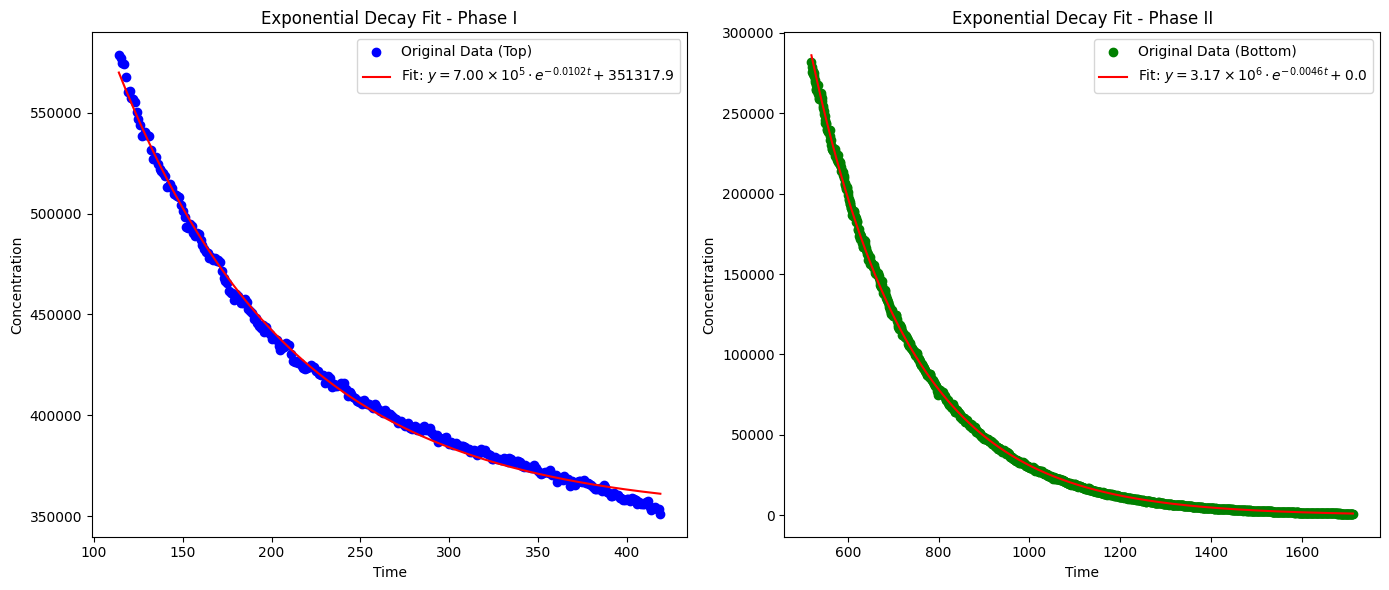

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Step 1: Define exponential decay model
def exp_decay(t, A, k, C):
    return A * np.exp(-k * t) + C

# Step 2: Load your actual data here
# Example:
# time1 = np.array([...])
# concentration1 = np.array([...])

# Step 3: Define cutoff points
top_start = 114
top_end = 420
bottom_start = 520
bottom_end = 1713

# Step 4: Slice data
t_top = time1[top_start:top_end]
c_top = concentration1[top_start:top_end]
t_bottom = time1[bottom_start:bottom_end]
c_bottom = concentration1[bottom_start:bottom_end]

# Step 5: Fit exponential decay to both regions with bounds (to keep C ≥ 0)
bounds = ([0, 0, 0], [np.inf, np.inf, np.inf])

popt_top, _ = curve_fit(exp_decay, t_top, c_top, p0=(1e6, 0.01, 1e5), bounds=bounds, maxfev=10000)
fit_top = exp_decay(t_top, *popt_top)

popt_bottom, _ = curve_fit(exp_decay, t_bottom, c_bottom, p0=(1e6, 0.005, 1e5), bounds=bounds, maxfev=10000)
fit_bottom = exp_decay(t_bottom, *popt_bottom)

# Step 6: Plotting
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Function to format coefficient in LaTeX scientific notation
def sci_notation_latex(num):
    coeff = f"{num:.2e}".split("e")[0]
    exponent = int(f"{num:.2e}".split("e")[1])
    return rf"{coeff} \times 10^{{{exponent}}}"

# LaTeX-formatted equations for legend
top_eq = rf'Fit: $y = {sci_notation_latex(popt_top[0])} \cdot e^{{-{popt_top[1]:.4f}t}} + {popt_top[2]:.1f}$'
bottom_eq = rf'Fit: $y = {sci_notation_latex(popt_bottom[0])} \cdot e^{{-{popt_bottom[1]:.4f}t}} + {popt_bottom[2]:.1f}$'


# Top plot
ax[0].scatter(t_top, c_top, label='Original Data (Top)', color='blue')
ax[0].plot(t_top, fit_top, label=top_eq, color='red')
ax[0].set_title("Exponential Decay Fit - Phase I")
ax[0].set_xlabel("Time")
ax[0].set_ylabel("Concentration")
ax[0].legend()

# Bottom plot
ax[1].scatter(t_bottom, c_bottom, label='Original Data (Bottom)', color='green')
ax[1].plot(t_bottom, fit_bottom, label=bottom_eq, color='red')
ax[1].set_title("Exponential Decay Fit - Phase II")
ax[1].set_xlabel("Time")
ax[1].set_ylabel("Concentration")
ax[1].legend()

plt.tight_layout()
plt.show()

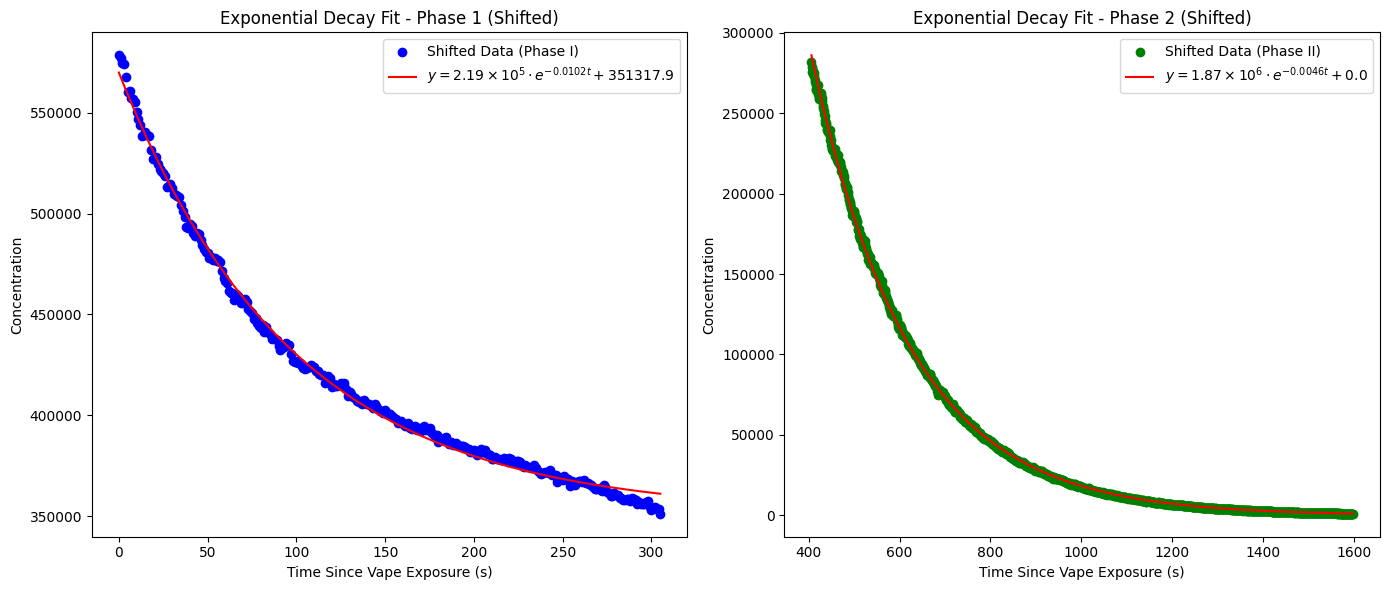

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# --- Exponential decay model ---
def exp_decay(t, A, k, C):
    return A * np.exp(-k * t) + C

# --- Vape exposure time ---
vape_exposure_time = time1[phase_one_start]  # time at max concentration

# --- Shift times so that vape exposure = 0 ---
t_top_shifted = t_top - vape_exposure_time
t_bottom_shifted = t_bottom - vape_exposure_time

# --- Refit the shifted data ---
popt_top_shifted, _ = curve_fit(exp_decay, t_top_shifted, c_top, p0=(1e6, 0.01, 1e5), bounds=([0, 0, 0], [np.inf, np.inf, np.inf]), maxfev=10000)
fit_top_shifted = exp_decay(t_top_shifted, *popt_top_shifted)

popt_bottom_shifted, _ = curve_fit(exp_decay, t_bottom_shifted, c_bottom, p0=(1e6, 0.005, 1e5), bounds=([0, 0, 0], [np.inf, np.inf, np.inf]), maxfev=10000)
fit_bottom_shifted = exp_decay(t_bottom_shifted, *popt_bottom_shifted)

# --- LaTeX formatting for equations ---
def sci_notation_latex(num):
    coeff = f"{num:.2e}".split("e")[0]
    exponent = int(f"{num:.2e}".split("e")[1])
    return rf"{coeff} \times 10^{{{exponent}}}"

top_eq_shifted = rf'$y = {sci_notation_latex(popt_top_shifted[0])} \cdot e^{{-{popt_top_shifted[1]:.4f}t}} + {popt_top_shifted[2]:.1f}$'
bottom_eq_shifted = rf'$y = {sci_notation_latex(popt_bottom_shifted[0])} \cdot e^{{-{popt_bottom_shifted[1]:.4f}t}} + {popt_bottom_shifted[2]:.1f}$'

# --- Plot shifted data ---
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Phase 1 shifted
ax[0].scatter(t_top_shifted, c_top, label="Shifted Data (Phase I)", color="blue")
ax[0].plot(t_top_shifted, fit_top_shifted, "r", label=top_eq_shifted)
ax[0].set_title("Exponential Decay Fit - Phase 1 (Shifted)")
ax[0].set_xlabel("Time Since Vape Exposure (s)")
ax[0].set_ylabel("Concentration")
ax[0].legend(loc="upper right")

# Phase 2 shifted
ax[1].scatter(t_bottom_shifted, c_bottom, label="Shifted Data (Phase II)", color="green")
ax[1].plot(t_bottom_shifted, fit_bottom_shifted, "r", label=bottom_eq_shifted)
ax[1].set_title("Exponential Decay Fit - Phase 2 (Shifted)")
ax[1].set_xlabel("Time Since Vape Exposure (s)")
ax[1].set_ylabel("Concentration")
ax[1].legend(loc="upper right")

plt.tight_layout()
plt.show()


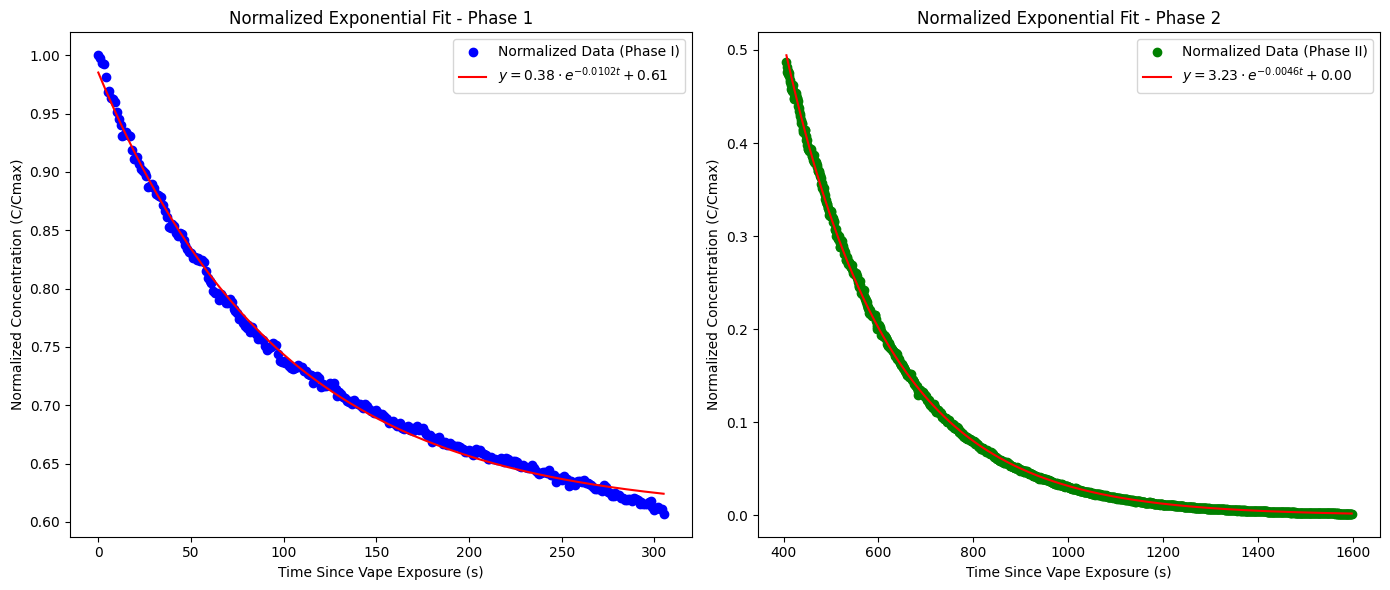

In [ ]:
# --- Normalization of concentration ---
max_conc = max(np.max(c_top), np.max(c_bottom))

c_top_norm = c_top / max_conc
c_bottom_norm = c_bottom / max_conc

# --- Refit exponential decay model on normalized data ---
popt_top_norm, _ = curve_fit(exp_decay, t_top_shifted, c_top_norm,
                             p0=(1, 0.01, 0), bounds=([0, 0, 0], [np.inf, np.inf, 1]), maxfev=10000)
fit_top_norm = exp_decay(t_top_shifted, *popt_top_norm)

popt_bottom_norm, _ = curve_fit(exp_decay, t_bottom_shifted, c_bottom_norm,
                                p0=(1, 0.005, 0), bounds=([0, 0, 0], [np.inf, np.inf, 1]), maxfev=10000)
fit_bottom_norm = exp_decay(t_bottom_shifted, *popt_bottom_norm)

# --- LaTeX-formatted equations ---
top_eq_norm = rf'$y = {popt_top_norm[0]:.2f} \cdot e^{{-{popt_top_norm[1]:.4f}t}} + {popt_top_norm[2]:.2f}$'
bottom_eq_norm = rf'$y = {popt_bottom_norm[0]:.2f} \cdot e^{{-{popt_bottom_norm[1]:.4f}t}} + {popt_bottom_norm[2]:.2f}$'

# --- Plot normalized fits ---
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Phase 1 normalized
ax[0].scatter(t_top_shifted, c_top_norm, label="Normalized Data (Phase I)", color="blue")
ax[0].plot(t_top_shifted, fit_top_norm, "r", label=top_eq_norm)
ax[0].set_title("Normalized Exponential Fit - Phase 1")
ax[0].set_xlabel("Time Since Vape Exposure (s)")
ax[0].set_ylabel("Normalized Concentration (C/Cmax)")
ax[0].legend(loc="upper right")

# Phase 2 normalized
ax[1].scatter(t_bottom_shifted, c_bottom_norm, label="Normalized Data (Phase II)", color="green")
ax[1].plot(t_bottom_shifted, fit_bottom_norm, "r", label=bottom_eq_norm)
ax[1].set_title("Normalized Exponential Fit - Phase 2")
ax[1].set_xlabel("Time Since Vape Exposure (s)")
ax[1].set_ylabel("Normalized Concentration (C/Cmax)")
ax[1].legend(loc="upper right")

plt.tight_layout()
plt.show()


In [ ]:
# --- Print fitted parameters for both phases ---
print("=== Normalized Fit Parameters ===")
print(f"Phase 1 (Top): A = {popt_top_norm[0]:.4f}, k = {popt_top_norm[1]:.6f}, C = {popt_top_norm[2]:.4f}")
print(f"Phase 2 (Bottom): A = {popt_bottom_norm[0]:.4f}, k = {popt_bottom_norm[1]:.6f}, C = {popt_bottom_norm[2]:.4f}")


=== Normalized Fit Parameters ===
Phase 1 (Top): A = 0.3779, k = 0.010204, C = 0.6073
Phase 2 (Bottom): A = 3.2316, k = 0.004625, C = 0.0000
